##### Copyright 2018 The TensorFlow Authors.

In [1]:
#@title Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# An introduction to ANN

PS: Some of this has been inspired by the recent Udacity course: https://classroom.udacity.com/courses/ud187.

#Diode Equation (assume you are Shockley)

Lets think of the way  William Shockley might have found the diode equation. All he had with him were some measurements of $I_D$ given values for $V_D$.

We already know that the equation that he found to be the the best is $I_D = I_O (e^{V_D/V_T} - 1)$.

Lets assume that we have the following readings of $V_D$ = (0, 0.2, 0.4, 0.6, 0.7) .

Lets cheat and find the values for $I_D$. Assume that we have got these current values from complicated lab-based experiments. We are asked to act Shockly and find a model which can churn out values of $I_D$ given any value of $V_D$.

In [2]:
import matplotlib as mp
import matplotlib.pyplot          # needed so that mp.pyplot exists
import numpy as np

I_o = 3.2e-12
v_d = np.array([0,0.1, 0.2,0.22, 0.3, 0.35, 0.4,0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8],  dtype=float)
i_d = I_o*(np.exp(v_d/0.025) - 1)
print(i_d)

[0.00000000e+00 1.71514080e-10 9.53586556e-09 2.12263808e-08
 5.20812133e-07 3.84833051e-06 2.84355505e-05 2.10111898e-04
 1.55252862e-03 1.14717211e-02 8.47651908e-02 6.26334750e-01
 4.62802261e+00 3.41967187e+01 2.52681473e+02]


<table class="tfo-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/tensorflow/examples/courses/udacity_intro_to_tensorflow_for_deep_learning/l02c01_celsius_to_fahrenheit.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Run in Google Colab</a>
  </td>
  <td>
    <a target="_blank" href="https://github.com/tensorflow/examples/courses/udacity_intro_to_tensorflow_for_deep_learning/l02c01_celsius_to_fahrenheit.ipynb"><img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />View source on GitHub</a>
  </td>
</table>

The first step in any machine learning activitiy is to check how does the data "look" like!  

Dont forget that a lot of our intuitive gut feeling is based around vision. (We will talk more about this later.) This is exactly why methods like principal component analysis are extremely powerful.

So lets plot it.

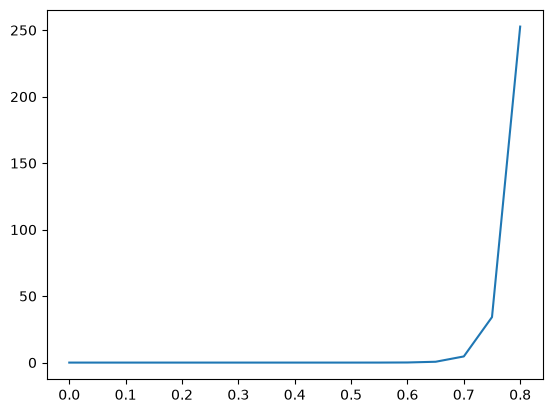

In [3]:
mp.pyplot.plot(v_d,i_d)

So from the plot what do you think the equation might be? Maybe its quadratic? Maybe its exponential. So if its exponential then it will look like $I_D = x (e^{yV_D} + p)$. So to get this trick to work we need to find these three **parameters**  and thats why such methods are called .....guess.....**parametric methods** (we will discuss more about this later!)

How would you find these parameters? What are the possible issues and benefits of this method?

**Answer.** With a parametric method the shape of the curve is chosen first and only its few numbers are fitted, normally by least squares: the parameters are adjusted until the squared difference between the curve and the measurements is as small as possible. For the diode there is an even simpler route. Above roughly 0.1 V the "−1" is negligible, so the logarithm of the current is a straight line in the voltage, and fitting a straight line gives both parameters directly. The cell below does this and recovers $V_T$ = 0.025 V and $I_0$ = 3.2 pA almost exactly, and predicts 10.3 A at 0.72 V.

The benefits are that two or three parameters can be found from a handful of measurements, that they have a physical meaning (saturation current, thermal voltage), and that the model can be trusted outside the measured range because it follows the physics. The weakness is that everything depends on guessing the right form. A quadratic fitted to the same points would also give some parameters, but they would mean nothing and the curve would fail between and beyond the points. The fit is also sensitive to how the error is measured: the currents span fourteen orders of magnitude, so plain least squares on the raw currents is decided almost entirely by the last two or three points.

In [4]:
# parametric fit: for V_D >= 0.1 V the "-1" is negligible, so ln(I_D) is a straight line in V_D
mask = v_d >= 0.1
slope, intercept = np.polyfit(v_d[mask], np.log(i_d[mask]), 1)
print(f"fitted 1/V_T = {slope:.3f} 1/V  ->  V_T = {1/slope:.5f} V   (true 0.025 V)")
print(f"fitted I_0   = {np.exp(intercept):.3e} A                 (true {I_o:.1e} A)")
print(f"predicted I_D at 0.72 V = {np.exp(intercept + slope*0.72):.3f} A   (true {I_o*(np.exp(0.72/0.025)-1):.3f} A)")

fitted 1/V_T = 40.011 1/V  ->  V_T = 0.02499 V   (true 0.025 V)
fitted I_0   = 3.179e-12 A                 (true 3.2e-12 A)
predicted I_D at 0.72 V = 10.315 A   (true 10.300 A)


Now lets jump to the other type of trick where we do not impose any "model" on the data. Rather, we expect the data to lead our way!

**In God we trust, rest others bring data!**...late Edwards Deming (father of lean startup)

Lets build a Neural Network to model this. I.e. it should be able to predict the current given the voltage.

## Import dependencies

First, import TensorFlow. Here, we're calling it `tf` for ease of use. We also tell it to only display errors.



In [5]:
from __future__ import absolute_import, division, print_function
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"      # only show TensorFlow errors
warnings.filterwarnings("ignore")
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

import numpy as np

## Set up training data

As we saw before, supervised Machine Learning is all about figuring out an algorithm, given a set of inputs and outputs. Since the task here is to create a model that can give diode current from the voltage, we shall use $I_0$ as the output and $V_D$ as the input.

### Some Machine Learning terminology

 - **Feature** — The input(s) to our model. In this case, a single value — the diode voltage in V.

 - **Labels** — The output our model predicts. In this case, a single value — the diode current in A.

 - **Example** — A pair of inputs/outputs used during training. In our case a pair of values from `V_D` and `I_D` at a specific index.


## Create the model

Next create the model. We will use a very simple model, a Dense network. Since the problem is straightforward, this network will require only a single layer, with a single neuron.

### Build a layer

We'll call the layer `l0` and create it by instantiating `tf.keras.layers.Dense` with the following configuration:

*   `input_shape=[1]` — This specifies that the input to this layer is a single value. That is, the shape is a one-dimensional array with one member. Since this is the first (and only) layer, that input shape is the input shape of the entire model. The single value is a floating point number, representing diode voltage.

*   `units=1` — This specifies the number of neurons in the layer. The number of neurons defines how many internal variables the layer has to try to learn how to solve the problem. Since this is the final layer, it is also the size of the model's output — a single float value representing diode current. (In a multi-layered network, the size and shape of the later would need to match the `input_shape` of the next layer.)


In [6]:
tf.keras.utils.set_random_seed(0)      # fixed seed, so the numbers quoted in the notes can be reproduced
l0 = tf.keras.layers.Dense(units=1, input_shape=[1])

### Assemble layers into the model

Once layers are defined, they need to be assembled into a model. The **Sequential model** definition takes a list of layers as argument, specifying the calculation order from the input to the output.

This model has just a single layer, l0.

In [7]:
model = tf.keras.Sequential([l0])

**Note**

You will often see the layers defined inside the model definition, rather than beforehand:

```python
model = tf.keras.Sequential([
  tf.keras.layers.Dense(units=1, input_shape=[1])
])
```

## Compile the model, with loss and optimizer functions

Before training, the model has to be compiled. When compiled for training, the model is given:

- **Loss function** — A way of measuring how far off predictions are from the desired outcome. (The measured difference is called the "loss".) REF: https://keras.io/losses/

- **Optimizer function** — A way of adjusting internal values in order to reduce the loss. REF: https://keras.io/optimizers/


In [8]:
model.compile(loss='mean_squared_error',
              optimizer=tf.keras.optimizers.Adam(0.1))

These are used during training (`model.fit()`, below) to first calculate the loss at each point, and then improve it. In fact, the act of calculating the current loss of a model and then improving it is precisely what training is.

During training, the optimizer function is used to calculate adjustments to the model's internal variables. The goal is to adjust the internal variables until the model (which is really a math function) mirrors the actual equation for converting $v_D$ to $I_D$.

TensorFlow uses numerical analysis to perform this tuning, and all this complexity is hidden from you so we will not go into the details here. What is useful to know about these parameters are:



One part of the Optimizer you may need to think about when building your own models is the learnign rate (`0.1` in the code above). This is the step size taken when adjusting values in the model. If the value is too small, it will take too many iterations to train the model. Too large, and accuracy goes down. Finding a good value often involves some trial and error, but the range is usually within 0.001 (default), and 0.1.

https://keras.io/models/sequential/

## Train the model

Train the model by calling the `fit` method.

During training, the model takes in v_d values, performs a calculation using the current internal variables (called "weights") and outputs values which are meant to be the i_d values. Since the weights are intially set randomly, the output will not be close to the correct value. The difference between the actual output and the desired output is calculated using the loss function, and the optimizer function directs how the weights should be adjusted.

This cycle of calculate, compare, adjust is controlled by the `fit` method. The first argument is the inputs, the second argument is the desired outputs. The `epochs` argument specifies how many times this cycle should be run, and the `verbose` argument controls how much output the method produces.

In [9]:
history = model.fit(v_d, i_d, epochs=5000, verbose=False)
print("Finished training the model")

Finished training the model


## Display training statistics

The `fit` method returns a history object. We can use this object to plot how the loss of our model goes down after each training epoch.

We'll use [Matplotlib](https://matplotlib.org/) to visualize this (you could use another tool). As you can see, our model improves very quickly at first, and then has a steady, slow improvement until it is very near "perfect" towards the end.



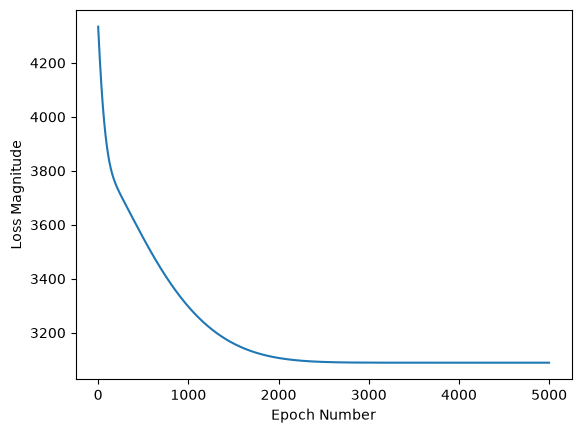

In [10]:
import matplotlib.pyplot as plt
plt.xlabel('Epoch Number')
plt.ylabel("Loss Magnitude")
plt.plot(history.history['loss'])

## Use the model to predict values

Now you have a model that has been trained to learn the relationshop between `v_d` and `i_d`. You can use the predict method to have it calculate the diode current. But unfortunately the error it converges to seems pretty bad. Lets try to use it anyway.

So, for example, if the diode voltage is 0.72 V then we expect a diode current of 10.3A. Lets see what we get.

In [11]:
print(model.predict(np.array([0.72]), verbose=0))

[[54.9359]]


##Post-mortem

Is this good? Hmmmmmmmm. Lets run another time.....But the error seems to be pretty high. What can we do now?

Mark that the model we used is linear. And we are trying to learn something which is exponential! Can we not add some nonlinearlity into the model? Try by adding a nonlinear activation function in the model and see what happens.

The error seems to be going down. Should we increase the number of epochs? Lets try that as well.






In [12]:
# post-mortem experiment: the same single neuron, but with a nonlinear (tanh) activation
tf.keras.utils.set_random_seed(0)
model_tanh = tf.keras.Sequential([tf.keras.layers.Dense(units=1, activation='tanh', input_shape=[1])])
model_tanh.compile(loss='mean_squared_error', optimizer=tf.keras.optimizers.Adam(0.1))
hist_tanh = model_tanh.fit(v_d, i_d, epochs=5000, verbose=False)
print("linear neuron: final loss", round(history.history['loss'][-1], 1))
print("tanh neuron:   final loss", round(hist_tanh.history['loss'][-1], 1))
print("tanh neuron prediction at 0.72 V:", model_tanh.predict(np.array([0.72]), verbose=0).ravel())
print("largest value the tanh neuron outputs on the training voltages:", model_tanh.predict(v_d, verbose=0).max())

linear neuron: final loss 3088.9
tanh neuron:   final loss 4297.7
tanh neuron prediction at 0.72 V: [0.9976632]
largest value the tanh neuron outputs on the training voltages: 0.99923605


**Answer.** The result is not good. A single neuron without an activation can only draw a straight line, and the best straight line through these points (weight 125.7, bias −35.6, printed further below) gives 54.9 A at 0.72 V instead of 10.3 A. The loss settles at about 3089 and more epochs cant lower it, because that value is already the best a straight line can do; the limit is the model, not the training.

Adding a nonlinearity to that single neuron does not help either, and here it makes things worse. The output of tanh can never exceed 1, while the currents go up to 253 A, so the neuron saturates at 1 and the loss rises to about 4298. The cell above shows it: the prediction at 0.72 V is 0.998 A. A nonlinear activation is useful in a hidden layer, where many such curves are combined, but the output neuron has to stay linear so that it can reach any value. That is the structure used in the next experiment.

## Looking at the layer weights

Finally, let's print the internal variables of the Dense layer.

In [13]:
print("These are the layer variables: {}".format(l0.get_weights()))

These are the layer variables: [array([[125.72288]], dtype=float32), array([-35.584576], dtype=float32)]


### Some more experiments

Something is not going well. What can we do? Can we add more layers?

Universal approximation theorem.
A single hidden layer can approximate any function!

Finished training the model
[[9.025453]]


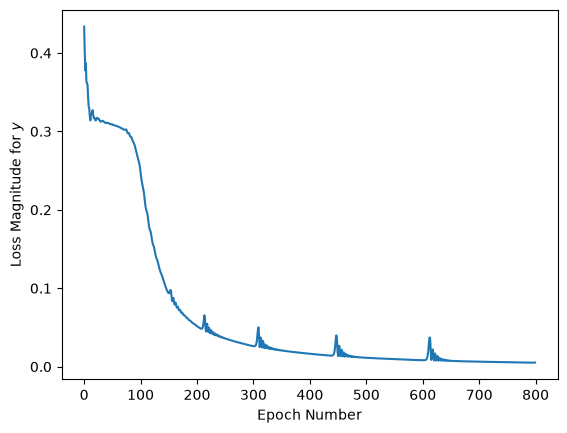

In [14]:
tf.keras.utils.set_random_seed(0)
l0 = tf.keras.layers.Dense(units=850, activation='tanh',input_shape=[1])
l1 = tf.keras.layers.Dense(units=1)
model = tf.keras.Sequential([l0, l1])
model.compile(loss='mean_squared_error', optimizer=tf.keras.optimizers.Adam(0.1))
history = model.fit(v_d, i_d, epochs=800, verbose=False)
print("Finished training the model")
print(model.predict(np.array([0.72]), verbose=0))
#print("Model predicts that 100 degrees Celsius is: {} degrees Fahrenheit".format(model.predict([0.72])))
#print("These are the l0 variables: {}".format(l0.get_weights()))
#print("These are the l1 variables: {}".format(l1.get_weights()))
#print("These are the l2 variables: {}".format(l2.get_weights()))
ppp = history.history['loss']
qqq = np.multiply(ppp,0.0001)
plt.xlabel('Epoch Number')
plt.ylabel("Loss Magnitude for $y$")
plt.plot(qqq)

##Play-around

We still did not get anything decent. But the theory says it should work. Try increasing the number of nodes in the hidden layer and see what happens.

So which is better? Parametric or data-centered ANN approach?

What else did you learn from this?

true I_D at 0.72 V = 10.30 A, at 0.775 V = 92.96 A



   10 tanh nodes,  800 epochs: final loss     1.692 | I_D(0.72) =   6.72 A | I_D(0.775) =  129.52 A


  100 tanh nodes,  800 epochs: final loss     1.951 | I_D(0.72) =   4.48 A | I_D(0.775) =  116.44 A


  850 tanh nodes,  800 epochs: final loss    52.487 | I_D(0.72) =   9.03 A | I_D(0.775) =  138.14 A


 3000 tanh nodes,  800 epochs: final loss   767.158 | I_D(0.72) =  60.11 A | I_D(0.775) =  139.78 A


  850 tanh nodes, 5000 epochs: final loss     1.417 | I_D(0.72) =   4.10 A | I_D(0.775) =  114.98 A


  100 relu nodes, 5000 epochs: final loss     0.024 | I_D(0.72) =   9.28 A | I_D(0.775) =  137.64 A


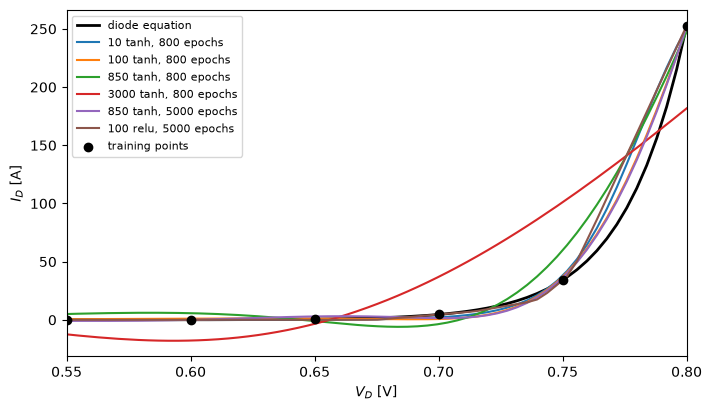

In [15]:
# play-around: how does the number of hidden nodes change the result?
def diode_net(hidden_units, activation, epochs, y=i_d, lr=0.1):
    tf.keras.utils.set_random_seed(0)
    layers = [tf.keras.Input(shape=(1,))]
    if hidden_units:
        layers.append(tf.keras.layers.Dense(hidden_units, activation=activation))
    layers.append(tf.keras.layers.Dense(1))
    net = tf.keras.Sequential(layers)
    net.compile(loss='mean_squared_error', optimizer=tf.keras.optimizers.Adam(lr))
    hist = net.fit(v_d, y, epochs=epochs, verbose=False)
    return net, hist.history['loss'][-1]

v_new = np.array([0.72, 0.775])                      # voltages that are not in the training set
i_new = I_o*(np.exp(v_new/0.025) - 1)
v_plot = np.linspace(0, 0.8, 200)
print(f"true I_D at 0.72 V = {i_new[0]:.2f} A, at 0.775 V = {i_new[1]:.2f} A\n")

plt.figure(figsize=(8, 4.5))
plt.plot(v_plot, I_o*(np.exp(v_plot/0.025) - 1), 'k', lw=2, label='diode equation')
for units, act, epochs in [(10, 'tanh', 800), (100, 'tanh', 800), (850, 'tanh', 800), (3000, 'tanh', 800),
                           (850, 'tanh', 5000), (100, 'relu', 5000)]:
    net, loss = diode_net(units, act, epochs)
    p = net.predict(v_new, verbose=0).ravel()
    print(f"{units:5d} {act} nodes, {epochs:4d} epochs: final loss {loss:9.3f} | I_D(0.72) = {p[0]:6.2f} A | I_D(0.775) = {p[1]:7.2f} A")
    plt.plot(v_plot, net.predict(v_plot, verbose=0), label=f'{units} {act}, {epochs} epochs')
plt.scatter(v_d, i_d, c='k', zorder=3, label='training points')
plt.xlim(0.55, 0.8); plt.xlabel('$V_D$ [V]'); plt.ylabel('$I_D$ [A]'); plt.legend(fontsize=8)
plt.show()

In [16]:
# the same single linear neuron as at the start, but trained on ln(I_D) instead of I_D
log_net, log_loss = diode_net(0, None, 2000, y=np.log(i_d + I_o))
w, b = [float(x.ravel()[0]) for x in log_net.get_weights()]
p = np.exp(log_net.predict(v_new, verbose=0).ravel()) - I_o
print(f"final loss (in log units) {log_loss:.2e}")
print(f"learned weight {w:.3f} (1/V_T = 40), learned bias {b:.3f} (ln I_0 = {np.log(I_o):.3f})")
print(f"I_D(0.72) = {p[0]:.3f} A, I_D(0.775) = {p[1]:.3f} A")

final loss (in log units) 7.70e-10
learned weight 40.000 (1/V_T = 40), learned bias -26.468 (ln I_0 = -26.468)
I_D(0.72) = 10.300 A, I_D(0.775) = 92.953 A


**Answer.** Adding a hidden layer does make the network nonlinear, and the loss falls from about 3089 to a few units, but more nodes did not make it better. With 800 epochs the loss was 1.7 for 10 nodes, 2.0 for 100, 52 for 850 and 767 for 3000. The larger the layer, the harder it was to train with the same learning rate and the same number of epochs; the 3000-node network is visibly still far from the points in the plot. Giving the 850-node network 5000 epochs brought its loss down to 1.4, which shows that the large network was under-trained, not incapable. The universal approximation theorem only says that suitable weights exist. It does not say that the optimiser will find them, or how long that takes.

A low loss on the training points also says little about the curve between them. The 850-node network after 800 epochs predicts 9.0 A at 0.72 V, which looks close to the true 10.3 A, but its loss is the second worst, so this is luck. The ReLU network has the lowest loss of all (0.02) and still gives 137.6 A at 0.775 V, where the true value is 93.0 A, because between two training points it simply draws a straight line. All the networks do something similar between 0.75 V and 0.8 V, as the plot shows. With 15 points and hundreds or thousands of weights, the network is free to do anything between the measurements.

For this problem the parametric approach is better, cause it needs two parameters, it reproduces the current at unseen voltages, and the parameters mean something. The ANN is the right tool when nobody knows the form of the function, and then it needs far more data than 15 points and gives no guarantee outside the range it was trained on.


# Chosen lab task: classifying Sentinel-2 patches as urban or forest (Task 1)

Task 1 is solved here. Task 2 (estimating the season from Sentinel-5P data) was not attempted.

## 1. The task as a function

A patch is a 200 × 200 pixel piece of a satellite image with three colour channels, nothing more than 120 000 numbers. The tag we have is one of two words, also could be written as a single number: 0 - forest and 1 - urban. The task is therefore a function that takes 120 000 numbers and returns one number. The network is a function with adjustable weights, and training changes the weights until its outputs agree with the examples.

In practice the network returns a number between 0 and 1, which is probability that the patch is urban. The patch is tagged urban when this number is above 0.5 and forest otherwise.

## 2. Training data

The data come from the same source as in Lab 3, the Sentinel-2 cloudless mosaic (EOX, 2020, true-colour RGB), downloaded at 10 m per pixel with `download_data.py`, so 200 × 200 patch covers 2 km × 2 km. Each scene is cut into a regular grid of patches that do not overlap, and the tag of a patch comes from the scene it was cut from: city centres give urban patches and large forest complexes give forest patches.

No scene is pure - cities contain rivers and parks, and forest scenes have villages and fields. Every scene was inspected with the grid on it and the patches that are clearly mixed or belong to neither class were removed; these are the positions listed in `drop`. What remains is still not perfectly clean which is realistic.

The training urban patches come from Warszawa, Łódź, Wrocław, Poznań and Katowice and for forest from the Białowieża, Notecka, Dolnośląskie and Tucholskie forests. The test patches come from different places altogether: Kraków and Gdańsk, and the Niepołomice, Kampinos and Augustów forests. Neighbouring patches of one scene look alike, so testing on patches from the training scenes would give a result that is too optimistic. Testing on other cities and forests checks whether the network learned something general.

In [17]:
import time
from PIL import Image

PATCH = 200                                  # patch side in pixels (2 km on the ground)

def grid(rows, cols, drop=()):
    # all (row, col) patch positions of a scene except the ones listed in drop
    return [(r, c) for r in range(rows) for c in range(cols) if (r, c) not in set(drop)]

# scene: (subset, label, patch positions).  Label 0 = forest, 1 = urban.
SCENES = {
    "urban_warszawa":      ("train", 1, grid(5, 6, [(1,1), (3,5), (4,4), (4,5)])),
    "urban_lodz":          ("train", 1, grid(4, 5, [(1,0), (2,0), (3,0), (1,4)])),
    "urban_wroclaw":       ("train", 1, grid(4, 5, [(0,1), (2,0), (1,4), (2,4), (3,4)])),
    "urban_poznan":        ("train", 1, grid(4, 5, [(0,0), (0,1), (1,0), (2,4), (3,2)])),
    "urban_katowice":      ("train", 1, grid(4, 6, [(0,0), (0,3), (0,5), (1,0), (1,3), (2,0), (3,1), (3,2), (3,5)])),
    "forest_bialowieza":   ("train", 0, grid(5, 6, [(2,0), (2,1), (3,3), (3,5), (4,4), (4,5)])),
    "forest_notecka":      ("train", 0, grid(4, 6, [(2,5), (3,3), (3,4), (3,5)])),
    "forest_dolnoslaskie": ("train", 0, grid(4, 6, [(3,0), (3,1), (3,2)])),
    "forest_tucholskie":   ("train", 0, [(1,0), (1,2), (2,0), (2,2), (2,3), (3,2), (3,3)]),
    "urban_krakow":        ("test",  1, grid(4, 5, [(2,0), (2,3), (3,0), (3,2)])),
    "urban_gdansk":        ("test",  1, grid(4, 4, [(0,0), (1,0), (1,1), (2,0), (2,2)])),
    "forest_niepolomice":  ("test",  0, [(1,3), (1,4), (2,1), (2,2), (2,3), (2,4)]),
    "forest_kampinos":     ("test",  0, [(1,2), (1,5), (2,0), (2,1), (2,2), (2,4), (2,5)]),
    "forest_augustowska":  ("test",  0, grid(4, 5, [(0,0), (0,1), (0,2), (0,3), (1,1)])),
}

patches = {"train": [], "test": []}
labels  = {"train": [], "test": []}
for name, (subset, label, cells) in SCENES.items():
    img = np.asarray(Image.open(f"data/{name}.jpg").convert("RGB"))
    for r, c in cells:
        patches[subset].append(img[r*PATCH:(r+1)*PATCH, c*PATCH:(c+1)*PATCH])
        labels[subset].append(label)
    print(f"{name:20s} {subset:5s} {'urban' if label else 'forest':6s} {len(cells):3d} patches")

# scale the pixel values from 0..255 to 0..1
X_train_all = np.array(patches["train"], dtype=np.float32) / 255.0
y_train_all = np.array(labels["train"],  dtype=np.float32)
X_test      = np.array(patches["test"],  dtype=np.float32) / 255.0
y_test      = np.array(labels["test"],   dtype=np.float32)
print()
print("training set:", X_train_all.shape, f"- {int(y_train_all.sum())} urban, {int((1-y_train_all).sum())} forest")
print("test set:    ", X_test.shape,      f"- {int(y_test.sum())} urban, {int((1-y_test).sum())} forest")

urban_warszawa       train urban   26 patches
urban_lodz           train urban   16 patches
urban_wroclaw        train urban   15 patches
urban_poznan         train urban   15 patches
urban_katowice       train urban   15 patches
forest_bialowieza    train forest  24 patches
forest_notecka       train forest  20 patches
forest_dolnoslaskie  train forest  21 patches
forest_tucholskie    train forest   7 patches
urban_krakow         test  urban   16 patches
urban_gdansk         test  urban   11 patches
forest_niepolomice   test  forest   6 patches
forest_kampinos      test  forest   7 patches
forest_augustowska   test  forest  15 patches

training set: (159, 200, 200, 3) - 87 urban, 72 forest
test set:     (55, 200, 200, 3) - 27 urban, 28 forest


There are 159 training patches (87 urban, 72 forest) and 55 test patches (27 urban, 28 forest), so the classes are close to balanced and plain accuracy is a fair measure. The pixel values are divided by 255 so that all inputs lie between 0 and 1. With inputs in the hundreds the weighted sums inside the network would be huge and training would be unstable.

Before building anything it is worth looking at the data, as the diode part of this notebook recommends.

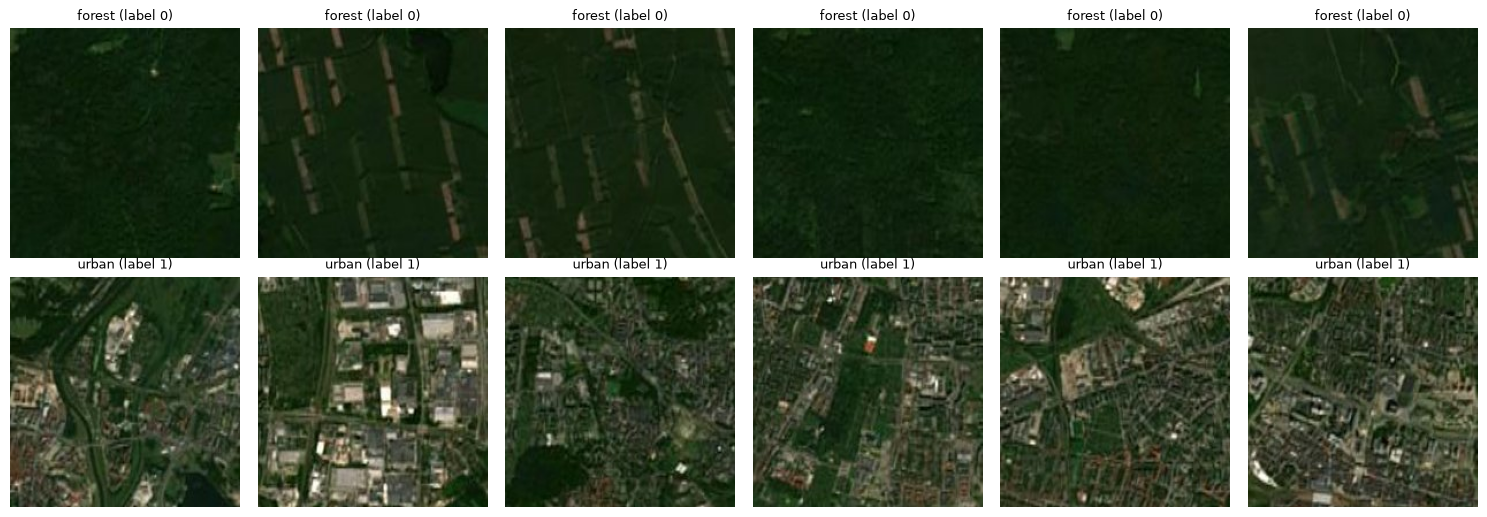

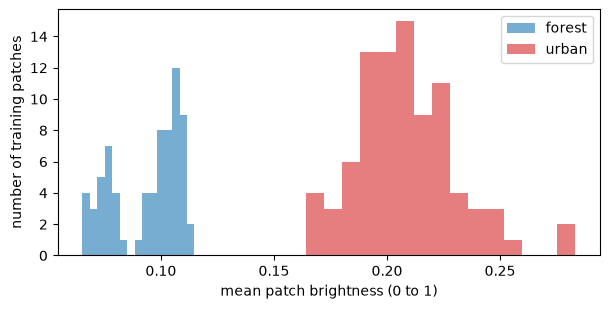

forest patches: brightness 0.065 to 0.115
urban patches:  brightness 0.164 to 0.283


In [18]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
for row, (label, name) in enumerate([(0, "forest"), (1, "urban")]):
    for ax, i in zip(axes[row], rng.choice(np.where(y_train_all == label)[0], 6, replace=False)):
        ax.imshow(X_train_all[i]); ax.set_title(f"{name} (label {label})", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

# mean brightness of every training patch
brightness = X_train_all.mean(axis=(1, 2, 3))
plt.figure(figsize=(7, 3.2))
plt.hist(brightness[y_train_all == 0], bins=15, alpha=0.6, color="tab:blue", label="forest")
plt.hist(brightness[y_train_all == 1], bins=15, alpha=0.6, color="tab:red",  label="urban")
plt.xlabel("mean patch brightness (0 to 1)"); plt.ylabel("number of training patches"); plt.legend(); plt.show()
print(f"forest patches: brightness {brightness[y_train_all == 0].min():.3f} to {brightness[y_train_all == 0].max():.3f}")
print(f"urban patches:  brightness {brightness[y_train_all == 1].min():.3f} to {brightness[y_train_all == 1].max():.3f}")

The two classes look very different. Forest is dark, a city is brighter and full of texture. The histogram shows that the mean brightness of a patch alone separates them completely in the training set: forest patches lie between 0.065 and 0.115, urban patches between 0.164 and 0.283, with a gap in between. This says in advance that the problem is easy and that even a very simple model should solve it.

One fifth of the training patches is set aside as a validation set. It is not used to adjust the weights.

In [19]:
# hold back 20 % of the training patches for validation
order = np.random.default_rng(0).permutation(len(X_train_all))
n_val = len(X_train_all) // 5
val_idx, train_idx = order[:n_val], order[n_val:]
X_train, y_train = X_train_all[train_idx], y_train_all[train_idx]
X_val,   y_val   = X_train_all[val_idx],   y_train_all[val_idx]
print(f"train {len(X_train)} patches, validation {len(X_val)} patches, test {len(X_test)} patches")

train 128 patches, validation 31 patches, test 55 patches


## 3. The barebone architecture

The smallest network that can do this job has no hidden layer, te patch is flattened into a vector of 120 000 numbers, and all of them are connected to a single output neuron with a sigmoid activation, which squeezes the weighted sum into the range 0 to 1 so that it can be read as the probability of the urban class. This gives 120 000 weights and one bias, 120 001 parameters in total. Without a hidden layer the network can only draw a flat boundary between the classes (the same as logistic regression), which is the right starting point.

The loss is binary cross-entropy, the standard choice for a yes/no output: it is small when the network gives a high probability to the correct class and grows quickly when the network is confident and wrong. The optimiser for the baseline is plain stochastic gradient descent with a learning rate of 0.01, the simplest one available. Training runs for 50 epochs with 16 patches per step.

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 120000)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │       120,001 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,003 (468.77 KB)

 Trainable params: 120,001 (468.75 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

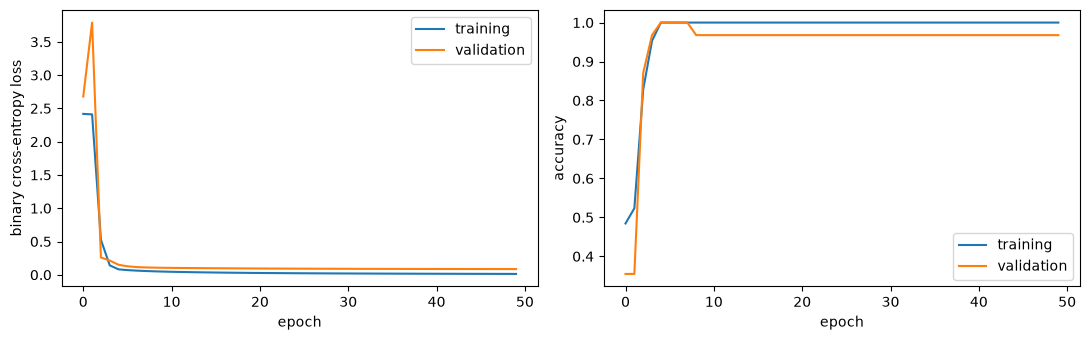

training time 1.2 s
accuracy: train 1.000 | validation 0.968 | test 1.000
test confusion matrix (rows: true forest/urban, columns: predicted forest/urban)
 [[28  0]
 [ 0 27]]


In [20]:
def build_model(hidden=(), activation="relu"):
    # Flatten -> optional hidden Dense layers -> one sigmoid output neuron
    layers = [tf.keras.Input(shape=(PATCH, PATCH, 3)), tf.keras.layers.Flatten()]
    layers += [tf.keras.layers.Dense(n, activation=activation) for n in hidden]
    layers += [tf.keras.layers.Dense(1, activation="sigmoid")]
    return tf.keras.Sequential(layers)

def train_model(hidden=(), activation="relu", optimizer="sgd", lr=0.01, epochs=50, seed=0):
    tf.keras.utils.set_random_seed(seed)
    model = build_model(hidden, activation)
    opt = {"sgd": tf.keras.optimizers.SGD, "adam": tf.keras.optimizers.Adam}[optimizer](lr)
    model.compile(loss="binary_crossentropy", optimizer=opt, metrics=["accuracy"])
    t0 = time.time()
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs, batch_size=16, verbose=0)
    return model, hist.history, time.time() - t0

baseline, base_hist, base_time = train_model()      # no hidden layer, plain SGD
baseline.summary()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(base_hist["loss"], label="training"); axes[0].plot(base_hist["val_loss"], label="validation")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("binary cross-entropy loss"); axes[0].legend()
axes[1].plot(base_hist["accuracy"], label="training"); axes[1].plot(base_hist["val_accuracy"], label="validation")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()

def confusion(model, X, y):
    pred = (model.predict(X, verbose=0).ravel() > 0.5).astype(int)
    return np.array([[np.sum((y == t) & (pred == p)) for p in (0, 1)] for t in (0, 1)])

print(f"training time {base_time:.1f} s")
print(f"accuracy: train {base_hist['accuracy'][-1]:.3f} | validation {base_hist['val_accuracy'][-1]:.3f} | test {baseline.evaluate(X_test, y_test, verbose=0)[1]:.3f}")
print("test confusion matrix (rows: true forest/urban, columns: predicted forest/urban)\n", confusion(baseline, X_test, y_test))

## 4. Performance of the baseline

The baseline trains in about a second. The loss drops sharply within the first five epochs and then keeps decreasing slowly. The network classifies all 128 training patches correctly, 30 of the 31 validation patches (96.8 %), and all 55 test patches, which come from cities and forests it has never seen.

The cell below looks at what the network got wrong and at what it learned.

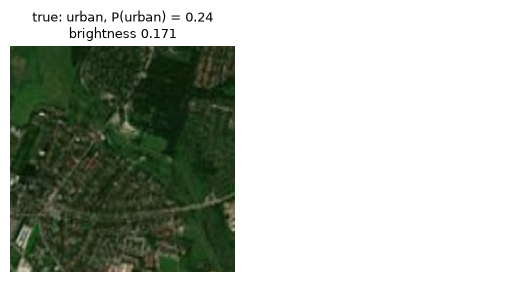

correlation between the network output (before the sigmoid) and patch brightness on the test set: 0.985
share of positive input weights: 53.4 %


In [21]:
# the validation patch(es) the baseline gets wrong
p_val = baseline.predict(X_val, verbose=0).ravel()
wrong = np.where((p_val > 0.5) != (y_val == 1))[0]
fig, axes = plt.subplots(1, max(len(wrong), 2), figsize=(3.2 * max(len(wrong), 2), 3.4))
for ax in axes: ax.axis("off")
for ax, i in zip(axes, wrong):
    ax.imshow(X_val[i])
    ax.set_title(f"true: {'urban' if y_val[i] else 'forest'}, P(urban) = {p_val[i]:.2f}\nbrightness {X_val[i].mean():.3f}", fontsize=9)
plt.show()

# how strongly does the output follow the mean brightness of the patch?
logit = lambda p: np.log(p / (1 - p))
p_test = np.clip(baseline.predict(X_test, verbose=0).ravel(), 1e-7, 1 - 1e-7)
print(f"correlation between the network output (before the sigmoid) and patch brightness on the test set: {np.corrcoef(logit(p_test), X_test.mean(axis=(1,2,3)))[0,1]:.3f}")
w = baseline.layers[-1].get_weights()[0].ravel()
print(f"share of positive input weights: {100 * (w > 0).mean():.1f} %")

The one validation mistake is a patch from the edge of a city, about half low-density housing and half vegetation. Its brightness (0.171) is at the very bottom of the urban range, and the network gives it a 24 % probability of being urban. This is a borderline tag as much as a network error.

The output of the network follows the mean brightness of the patch almost exactly (correlation 0.985 on the test set). The network has essentially learned to measure how bright a patch is, which is the feature the histogram pointed to. It is not a pure brightness sum, though: only 53 % of the weights are positive. With 120 001 weights and 128 examples there are endless combinations of weights that separate the training set, and gradient descent stops at one of them.

## 5. Permutations of the architecture

Nine configurations are compared. Starting from the baseline (A), the changes are: one hidden layer with 16 neurons (B), a much wider hidden layer with 128 neurons (C), two hidden layers (D), a sigmoid instead of ReLU activation in the hidden layer (E), and then the Adam optimiser instead of SGD on the baseline (F), on the 16-neuron network (G) and on the two-layer network (H), and finally Adam with a ten times larger learning rate (I).

The starting weights are random, every configuration is trained three times with different seeds, the table shows the average accuracy and the test accuracy of each run. For the ReLU networks the cell also counts how many neurons of the first hidden layer are still active after training, meaning that they give a non-zero output for at least one training patch.

In [22]:
CONFIGS = [   # name, hidden layers, activation, optimiser, learning rate
    ("A  no hidden layer, SGD (baseline)", (),       "relu",    "sgd",  0.01),
    ("B  1 hidden x 16, SGD",              (16,),    "relu",    "sgd",  0.01),
    ("C  1 hidden x 128, SGD",             (128,),   "relu",    "sgd",  0.01),
    ("D  2 hidden 64 + 32, SGD",           (64, 32), "relu",    "sgd",  0.01),
    ("E  1 hidden x 16 sigmoid, SGD",      (16,),    "sigmoid", "sgd",  0.01),
    ("F  no hidden layer, Adam",           (),       "relu",    "adam", 0.001),
    ("G  1 hidden x 16, Adam",             (16,),    "relu",    "adam", 0.001),
    ("H  2 hidden 64 + 32, Adam",          (64, 32), "relu",    "adam", 0.001),
    ("I  1 hidden x 16, Adam, lr 0.01",    (16,),    "relu",    "adam", 0.01),
]
SEEDS = (0, 1, 2)

def active_units(model):
    # number of first-hidden-layer neurons that give a non-zero output for at least one training patch
    first_hidden = tf.keras.Sequential(model.layers[:2])
    return int((first_hidden.predict(X_train, verbose=0) > 0).any(axis=0).sum())

results, curves = [], {}
print(f"{'configuration':36s} {'parameters':>11s} {'train':>6s} {'val':>6s} {'test':>6s}   test accuracy per seed   time/run")
for name, hidden, act, opt, lr in CONFIGS:
    runs = []
    for seed in SEEDS:
        model, hist, t = train_model(hidden, act, opt, lr, seed=seed)
        test_acc = model.evaluate(X_test, y_test, verbose=0)[1]
        alive = active_units(model) if hidden and act == "relu" else None
        runs.append((hist["accuracy"][-1], hist["val_accuracy"][-1], test_acc, t, alive))
        curves[(name, seed)] = hist["loss"]
    tr, va, te, tt = (np.mean([r[i] for r in runs]) for i in range(4))
    results.append((name, model.count_params(), tr, va, te, [r[2] for r in runs], tt, [r[4] for r in runs]))
    print(f"{name:36s} {model.count_params():>11,d} {tr:6.3f} {va:6.3f} {te:6.3f}   {'  '.join(f'{r[2]:.3f}' for r in runs)}      {tt:4.1f} s")

print("\nfirst-hidden-layer ReLU neurons still active after training (per seed):")
for name, *_, alive in results:
    if alive[0] is not None:
        print(f"{name:36s} {alive}")

configuration                         parameters  train    val   test   test accuracy per seed   time/run


A  no hidden layer, SGD (baseline)       120,001  1.000  0.968  1.000   1.000  1.000  1.000       1.2 s


B  1 hidden x 16, SGD                  1,920,033  1.000  0.978  1.000   1.000  1.000  1.000       1.4 s


C  1 hidden x 128, SGD                15,360,257  1.000  0.968  1.000   1.000  1.000  1.000       2.8 s


D  2 hidden 64 + 32, SGD               7,682,177  1.000  0.968  1.000   1.000  1.000  1.000       2.0 s


E  1 hidden x 16 sigmoid, SGD          1,920,033  1.000  0.968  1.000   1.000  1.000  1.000       1.3 s


F  no hidden layer, Adam                 120,001  1.000  0.968  1.000   1.000  1.000  1.000       1.2 s


G  1 hidden x 16, Adam                 1,920,033  0.865  0.763  0.830   1.000  1.000  0.491       1.8 s


H  2 hidden 64 + 32, Adam              7,682,177  1.000  0.968  1.000   1.000  1.000  1.000       3.2 s


I  1 hidden x 16, Adam, lr 0.01        1,920,033  0.729  0.559  0.661   1.000  0.491  0.491       1.8 s

first-hidden-layer ReLU neurons still active after training (per seed):
B  1 hidden x 16, SGD                [2, 4, 3]
C  1 hidden x 128, SGD               [34, 27, 48]
D  2 hidden 64 + 32, SGD             [15, 18, 25]
G  1 hidden x 16, Adam               [3, 1, 0]
H  2 hidden 64 + 32, Adam            [12, 15, 16]
I  1 hidden x 16, Adam, lr 0.01      [3, 0, 0]


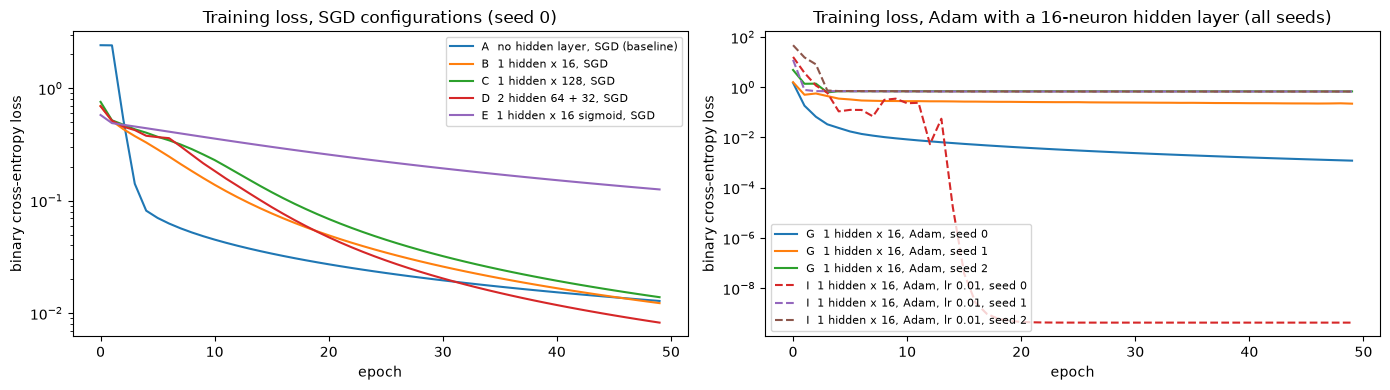

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for (name, seed), loss in curves.items():
    if seed == 0 and name[0] in "ABCDE":
        axes[0].plot(loss, label=name)
    if name[0] in "GI":
        axes[1].plot(loss, label=f"{name}, seed {seed}", ls="-" if name[0] == "G" else "--")
axes[0].set_title("Training loss, SGD configurations (seed 0)")
axes[1].set_title("Training loss, Adam with a 16-neuron hidden layer (all seeds)")
for ax in axes:
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("binary cross-entropy loss"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Findings

More nodes and more layers did not improve anything.
 Every configuration trained with SGD reaches 100 % on the test set in all three runs, the same as the baseline. The validation accuracy stays at 96.8%, the one borderline patch described above, apart from a single run of B that happens to get it right. There was nothing left to gain: the classes can already be separated with a flat boundary, so the extra capacity has nothing to do. Its cost is real and the 128-neuron network has 15.4 million parameters against 120 001, and takes more than twice as long to train for the same result.

The hidden layers are mostly idle.
 In the 16-neuron network only 2 to 4 neurons are active after training, and in the 128-neuron network 27 to 48. The reason is in the data: all inputs are positive and they rise and fall together with the brightness of the patch, so the weighted sum of a hidden neuron tends to have the same sign for every patch. If that sign is negative, ReLU outputs zero for every patch, no error signal reaches the neuron's weights, and it never recovers. The networks work because the few neurons that stay active are enough.

The optimiser mattered more than the architecture, and in the wrong direction.
 Working on the baseline and on the wider two-layer network, but with the 16-neuron hidden layer it failed in one run out of three and in two out of three with the larger learning rate. The failed runs have a test accuracy of 49.1%, which is the share of urban patches in the test set (27 of 55): the network gives the same answer for every patch. The count of active neurons explains it - it's 0 in each of runs. SGD changes each weight in proportion to its error signal. Moving every weight by the learning rate in its first steps and with 120 000 inputs feeding one neuron these small moves add up to a large shift of the weighted sum, which is enough to push all the neurons into the dead region at once, after which nothing can be learned and the loss stays flat near 0.69, so the value for a network that guesses. The wider network survives because with 64 neurons some always remain active. 

The activation mattered little.
 With a sigmoid in the hidden layer, the loss goes down more slowly, because of weaker error signal than ReLU, but the accuracy after 50 epochs is the same, sigmoid neurons also cannot die in the way ReLU neurons do.


## 7. Comparison with a Bayes classifier

The task description says that this exercise shows why a Bayesian classifier is preferred when it is possible. To check it, the cell below applies the method from Lab 3 to the same patches. 

In [24]:
# Gaussian Bayes classifier on three features per patch: the mean R, G and B (same method as in Lab 3)
def patch_features(X):
    return X.mean(axis=(1, 2))

def fit_gaussian(F):
    mu = F.mean(axis=0)
    D = F - mu
    return mu, D.T @ D / len(F)

def log_score(F, mu, Sigma, prior):
    D = F - mu
    maha = np.einsum("ij,jk,ik->i", D, np.linalg.inv(Sigma), D)
    return -0.5 * maha - 0.5 * np.log(np.linalg.det(Sigma)) + np.log(prior)

F_train, F_test = patch_features(X_train_all), patch_features(X_test)
t0 = time.time()
params = {c: fit_gaussian(F_train[y_train_all == c]) for c in (0, 1)}
bayes_pred = (log_score(F_test, *params[1], 0.5) > log_score(F_test, *params[0], 0.5)).astype(int)
print(f"fitted in {1000 * (time.time() - t0):.1f} ms, 18 parameters (two mean vectors and two symmetric 3x3 covariance matrices)")
print(f"Bayes test accuracy: {(bayes_pred == y_test).mean():.3f}")
print("class means (R, G, B): forest", params[0][0].round(3), "| urban", params[1][0].round(3))

fitted in 0.2 ms, 18 parameters (two mean vectors and two symmetric 3x3 covariance matrices)
Bayes test accuracy: 1.000
class means (R, G, B): forest [0.077 0.145 0.059] | urban [0.209 0.25  0.165]


The Bayes classifier also gets all 55 test patches right. It does so with 18 parameters instead of 120 001, it is fitted in shorter time by computing means and covariances, with no learning rate, epochs and random starting point, and so there is nothing that could fail the way previous runs did. Its parameters can be read directly: forest has a mean colour of about (0.08, 0.15, 0.06) and urban about (0.21, 0.25, 0.17). It gives a probability that is grounded in a model of the data, which is why the classes can be described by a simple distribution of a few well-chosen features, as they can here.

This is the same conclusion as in the diode part of the notebook - if the structure of the problem is known, a small model that uses that structure is cheaper, more reliable and easier to explain than a network. The ANN becomes worth its cost when no description exists: if the classes differed in texture or shape and not in overall brightness, three mean colours would not be enough, while a network could still learn from the raw pixels.

But we have to remember, that the dataset is small (159 training and 55 test patches), so it doesn't make a guarantee for us. Also the patches were chosen to be clear examples of each class - on mixed patches which the network has never seen, the results could be worse. Network treats each pixel position separately and would have to learn the same pattern again for every place in the patch -> oor match for images in general. 